# 🔁 Cross-Validation & 📈 ROC–AUC


In [6]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

df = pd.read_csv("/Users/shailesh/Desktop/vedam_Sem3_ml/Data/placement .csv")

# student_id -> ID column, package_lpa -> leaks the answer (not placed = no package)
X = df[["cgpa", "twelfth_percent", "internships", "projects",
        "backlogs", "prep_hours", "communication_score"]]
y = df["placed"]
X = X.fillna(X.median())

X.shape

(550, 7)

---
## 🔁 Part 1 — Cross-Validation

> **Flow:** one split → one lucky score → split the data into 5 parts → test on each part once → average

### 1.1 The problem with a single split
Same model, same data — only `random_state` changes (i.e. which rows go into the test set).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

model = DecisionTreeClassifier(max_depth=4, random_state=42)

for seed in [1, 2, 3]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    model.fit(X_train, y_train)
    print("random_state =", seed, "| accuracy =", accuracy_score(y_test, model.predict(X_test)))

random_state = 1 | accuracy = 0.7363636363636363
random_state = 2 | accuracy = 0.7727272727272727
random_state = 3 | accuracy = 0.7636363636363637


The model did not change — only the test rows did, and the accuracy moved with them. **One split = one lucky (or unlucky) score.**

### 1.2 The idea — K-Fold Cross-Validation
- Split the data into **K equal parts** (called *folds*). Here **K = 5**.
- **Round 1:** test on fold 1, train on folds 2–5.
- **Round 2:** test on fold 2, train on the rest … and so on for 5 rounds.
- Every row is tested **exactly once**.
- 5 rounds → **5 scores** → report their **average**.

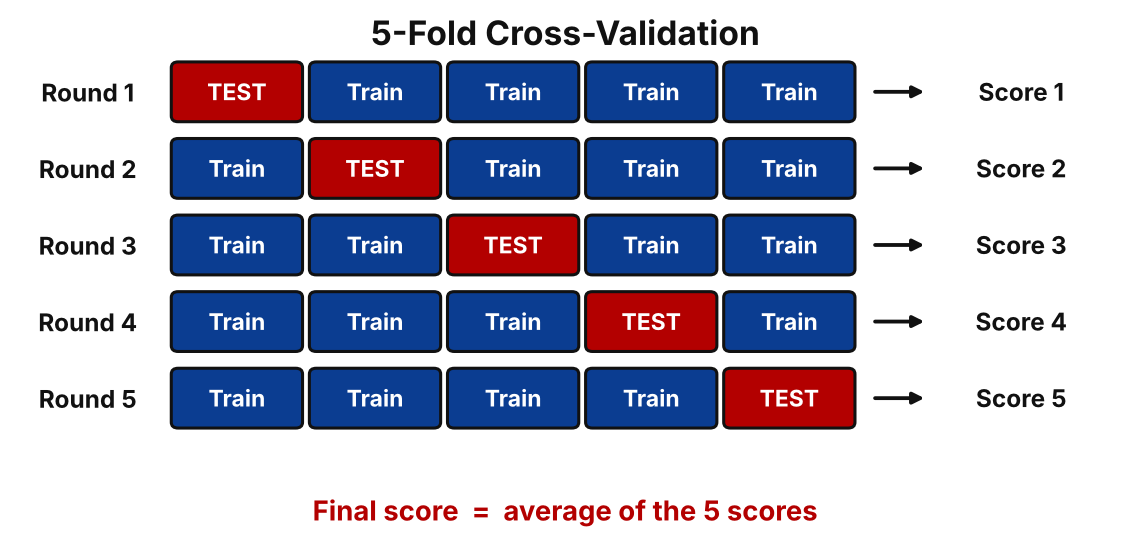

### 1.3 Code — `cross_val_score`

**Syntax**
```python
cross_val_score(model, X, y, cv=5)
```
| Argument | Meaning |
|---|---|
| `model` | any sklearn model — **no `.fit()` needed**, it trains the model itself in every round |
| `X, y` | features and target |
| `cv=5` | number of folds |
| **returns** | one score per fold |

In [4]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
scores = cross_val_score(model, X, y, cv=5)

print("Score in each fold:", scores)
print("Average score:", scores.mean())

Score in each fold: [0.7        0.76363636 0.7        0.76363636 0.76363636]
Average score: 0.7381818181818182


5 scores, one per fold. The **average** is the number we trust and report.

### 🧪 Practice — Cross-Validation

**P1.** SafeBank uses a decision tree (`max_depth=3`) to decide which loan applications to approve. The manager does not want a score from one lucky split.
Check the tree **5 times on different parts** of `loan_approval.csv`, then print all 5 scores and their average.

*The data is already loaded for you in the next cell.*

In [ ]:
# P1 — your code here

---
## 📈 Part 2 — ROC & AUC (Theory)

> **Flow:** probability → threshold → TPR & FPR → ROC curve → AUC

### 2.1 The model gives a probability
- For every row, a classifier first calculates the **probability of class 1** (e.g. probability of being placed).
- `predict()` turns that probability into 0 / 1 using a **threshold** — by default **0.5**:
  - probability ≥ 0.5 → **1**
  - probability < 0.5 → **0**
- The threshold **can be moved**. Moving it changes which rows are predicted as 1.

### 2.2 Two rates

| Rate | Formula | Meaning |
|---|---|---|
| **TPR** — True Positive Rate | **TP / (TP + FN)** | Of the students *actually placed*, how many did the model catch? (same as **Recall**) |
| **FPR** — False Positive Rate | **FP / (FP + TN)** | Of the students *actually not placed*, how many did the model wrongly mark as placed? |

**Goal:** TPR high, FPR low.

### 2.3 Worked example — 10 students
(P = placed, N = not placed → 5 P and 5 N)

| Student | S1 | S2 | S3 | S4 | S5 | S6 | S7 | S8 | S9 | S10 |
|---|---|---|---|---|---|---|---|---|---|---|
| **Probability** | 0.95 | 0.85 | 0.75 | 0.65 | 0.55 | 0.45 | 0.35 | 0.25 | 0.15 | 0.05 |
| **Actual** | P | P | N | P | P | N | P | N | N | N |

| Threshold | Predicted placed | TP | FP | TPR = TP / 5 | FPR = FP / 5 |
|---|---|---|---|---|---|
| 0.9 | S1 | 1 | 0 | 0.2 | 0.0 |
| 0.7 | S1 – S3 | 2 | 1 | 0.4 | 0.2 |
| 0.5 | S1 – S5 | 4 | 1 | 0.8 | 0.2 |
| 0.3 | S1 – S7 | 5 | 2 | 1.0 | 0.4 |
| 0.0 | All 10 | 5 | 5 | 1.0 | 1.0 |

**Lower threshold → more students predicted placed → TPR goes up, and FPR goes up too.**

### 2.4 ROC Curve
- Plot the point **(FPR, TPR)** for every threshold and join the points → **ROC curve** (Receiver Operating Characteristic).
- **Diagonal line** = random guessing.
- **Top-left corner** (FPR = 0, TPR = 1) = perfect model.
- The more the curve bends towards the top-left, the better the model.

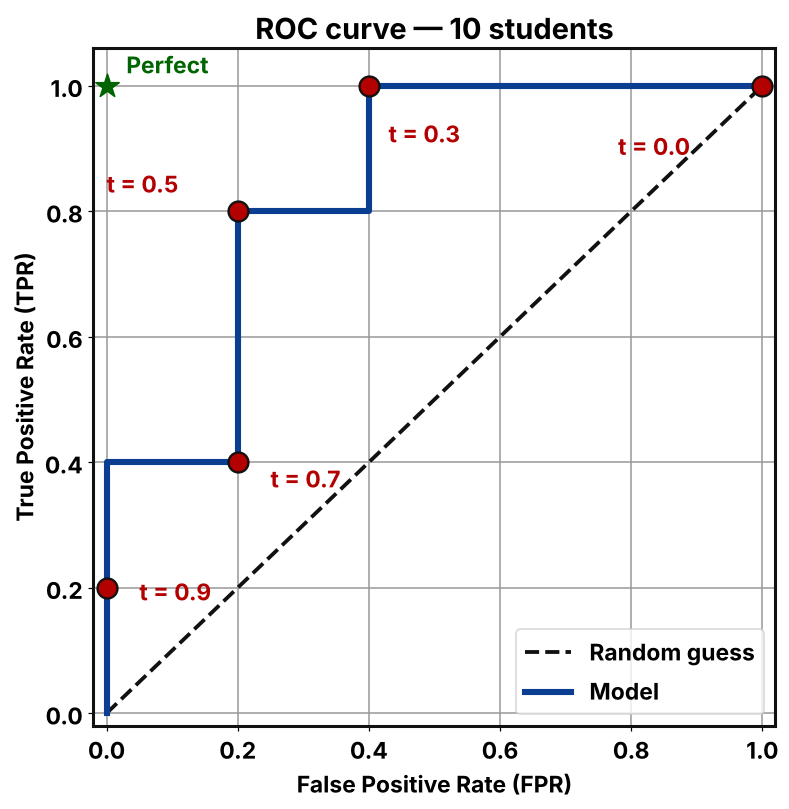

### 2.5 AUC — Area Under the Curve
AUC is the **area under the ROC curve** — one number between 0 and 1.

| AUC | Meaning |
|---|---|
| **1.0** | Perfect model |
| **0.5** | Random guessing (coin toss) |
| **below 0.5** | Worse than random |

**What the number means:** pick one placed and one not-placed student at random.
**AUC = chance that the model gives the placed student the higher probability.**

**Worked example:** 5 placed × 5 not placed = **25 pairs**. Count the pairs where the placed student has the higher probability:

| Placed student | Probability | Higher than how many N students? |
|---|---|---|
| S1 | 0.95 | 5 |
| S2 | 0.85 | 5 |
| S4 | 0.65 | 4 |
| S5 | 0.55 | 4 |
| S7 | 0.35 | 3 |
| | **Total** | **21** |

**AUC = 21 / 25 = 0.84**

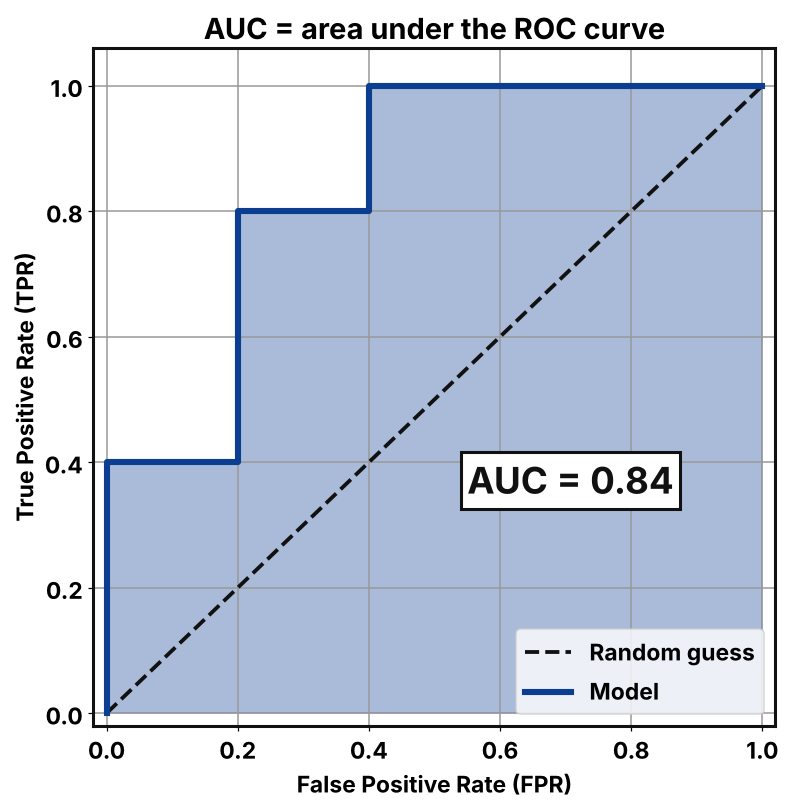

### 2.6 Comparing models with ROC–AUC
- Accuracy is measured at **one** threshold (0.5).
- AUC checks the model across **all** thresholds → a fairer way to compare two models.

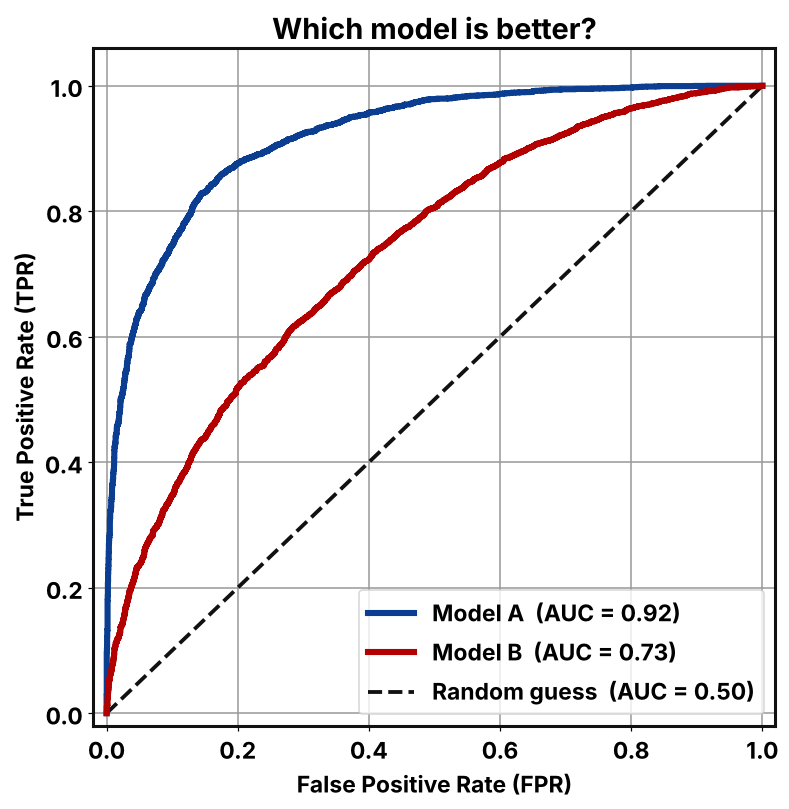

Model A's curve is closer to the top-left → higher AUC → better model.

### 🧪 Practice — ROC & AUC (by hand)

**P2.** The FitZone gym app gives each member a chance of renewing their membership:

| Member | M1 | M2 | M3 | M4 | M5 | M6 | M7 | M8 |
|---|---|---|---|---|---|---|---|---|
| **Chance of renewing** | 0.9 | 0.8 | 0.7 | 0.6 | 0.4 | 0.3 | 0.2 | 0.1 |
| **Actually renewed?** | Yes | No | Yes | Yes | No | Yes | No | No |

**(a)** The app expects a member to renew if the chance is **0.5 or more**.
- Out of the members who **actually renewed**, what fraction did the app catch?
- Out of the members who **did not renew**, what fraction did the app wrongly expect to renew?

**(b)** Repeat (a) with a cut-off of **0.25**.

**(c) Bonus:** Make every (renewed, not renewed) pair. In what fraction of pairs does the renewed member have the higher chance?

---
## 📝 Quiz

**Q1.** `cross_val_score(model, X, y, cv=5)` returns how many scores?
a) 1  b) 5  c) 10  d) depends on the number of rows

**Q2.** A dataset has 400 rows and `cv=5`. How many rows are tested in each round?
a) 400  b) 320  c) 80  d) 5

**Q3.** The same model gave 0.78, 0.86 and 0.81 with three different `random_state` values. Why?
a) The model is broken  b) Different rows landed in the test set  c) The data has missing values  d) `cv` was not set

**Q4.** The threshold is lowered from 0.5 to 0.3. What happens?
a) TPR goes down, FPR goes down  b) TPR goes up, FPR goes down  c) TPR and FPR both go up (or stay the same)  d) Nothing changes

**Q5.** A model has AUC = 0.52. This means:
a) Excellent model  b) Close to a coin toss  c) Worse than random  d) 52% accuracy

**Q6.** A point on the ROC curve at FPR = 0, TPR = 1 means:
a) Every placed student caught, no false alarm  b) Every placed student missed  c) Random guessing  d) Every student predicted as placed

---
## 🧾 Summary

| Concept | In one line |
|---|---|
| Single split | One score that depends on which rows landed in the test set |
| K-Fold CV | Split into K parts, test on each part once, average the K scores |
| `cross_val_score` | `cross_val_score(model, X, y, cv=5)` → one score per fold |
| Threshold | Cut-off on the probability; default 0.5 |
| TPR / FPR | TP / (TP + FN)  and  FP / (FP + TN) |
| ROC curve | TPR vs FPR for every threshold |
| AUC | Area under the ROC curve — 1 = perfect, 0.5 = random |

---
## ✅ Solutions
### P1

In [ ]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
loan_scores = cross_val_score(tree, LX, Ly, cv=5)

print("Score in each fold:", loan_scores)
print("Average score:", loan_scores.mean())

### P2
**(a) Cut-off 0.5** → app expects M1, M2, M3, M4 to renew
- Renewed members: M1, M3, M4, M6 → caught M1, M3, M4 → **3 / 4 = 0.75**
- Did not renew: M2, M5, M7, M8 → wrongly expected M2 → **1 / 4 = 0.25**

**(b) Cut-off 0.25** → app expects M1 – M6 to renew
- Caught M1, M3, M4, M6 → **4 / 4 = 1.0**
- Wrongly expected M2, M5 → **2 / 4 = 0.5**

**(c)** 4 × 4 = 16 pairs. M1 (0.9) beats 4, M3 (0.7) beats 3, M4 (0.6) beats 3, M6 (0.3) beats 2 → **12 / 16 = 0.75**

### Quiz
Q1 — b  Q2 — c  Q3 — b  Q4 — c  Q5 — b  Q6 — a